# Multimodal Xenium (gene + protein) with MuData tables in SpatialData

This notebook reads a **Xenium In Situ Gene and Protein Expression** run into a `SpatialData` object whose table is a
[`MuData`](https://mudata.scverse.org) object, with one modality per assay (`"rna"`, `"prot"`), and analyses both
modalities natively: QC and normalization per modality, clustering, gene vs protein comparison, spatial plots of both
modalities, spatial queries and saving to disk.

It uses the experimental MuData support developed on the `claude/mudata-support-sdata-c2tfjf` branches of
`spatialdata`, `spatialdata-io` and `spatialdata-plot`.

**Data**: the public 10x Genomics *Xenium V1 Protein Human Kidney tiny* dataset (21 MB): 358 cells, a 405-gene panel and
4 immune checkpoint proteins (PD-1, VISTA, PD-L1, LAG-3).

## 1. Install the development branches

Run this cell first, in a fresh kernel (Python >= 3.12). It installs the three packages from their branches in a single
`pip` call, so that `spatialdata-io` and `spatialdata-plot` use the development version of `spatialdata`.

In [ ]:
BRANCH = "claude/mudata-support-sdata-c2tfjf"
INSTALL_FROM_GITHUB = True  # set to False to use an environment where the branches are already installed

if INSTALL_FROM_GITHUB:
    packages = [
        f"spatialdata @ git+https://github.com/scverse/spatialdata@{BRANCH}",
        f"spatialdata-io @ git+https://github.com/scverse/spatialdata-io@{BRANCH}",
        f"spatialdata-plot @ git+https://github.com/scverse/spatialdata-plot@{BRANCH}",
        "muon",
        "leidenalg",
    ]
    %pip install --quiet {" ".join(f'"{p}"' for p in packages)}

In [2]:
import importlib.metadata

for package in ["spatialdata", "spatialdata-io", "spatialdata-plot", "mudata", "anndata", "scanpy", "muon"]:
    print(f"{package:>16}: {importlib.metadata.version(package)}")

     spatialdata: 0.8.1.dev40+gab593bf55
  spatialdata-io: 0.7.2.dev5+gc20cf480d.d20261016
spatialdata-plot: 0.4.4.dev1+g0365aafc1
          mudata: 0.4.1
         anndata: 0.13.4
          scanpy: 1.12.4
            muon: 0.2.0


In [3]:
import warnings
import zipfile
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import mudata as md
import muon as mu
import numpy as np
import pandas as pd
import scanpy as sc
import spatialdata_plot  # noqa: F401
from scipy.stats import spearmanr
from spatialdata_io import xenium

import spatialdata as sd

warnings.filterwarnings("ignore", category=FutureWarning)
sc.settings.verbosity = 0

## 2. Download the dataset

In [4]:
DATA = Path("data")
DATASET = "Xenium_V1_Protein_Human_Kidney_tiny"
url = f"https://cf.10xgenomics.com/samples/xenium/4.0.0/{DATASET}/{DATASET}_outs.zip"
bundle = DATA / f"{DATASET}_outs"
if not bundle.exists():
    DATA.mkdir(exist_ok=True)
    archive, _ = urlretrieve(url, DATA / f"{DATASET}_outs.zip")
    with zipfile.ZipFile(archive) as z:
        z.extractall(bundle)
sorted(p.name for p in bundle.iterdir())

['.end-of-run',
 'analysis.tar.gz',
 'analysis.zarr.zip',
 'analysis_summary.html',
 'aux_outputs.tar.gz',
 'cell_boundaries.csv.gz',
 'cell_boundaries.parquet',
 'cell_feature_matrix.h5',
 'cell_feature_matrix.tar.gz',
 'cell_feature_matrix.zarr.zip',
 'cells.csv.gz',
 'cells.parquet',
 'cells.zarr.zip',
 'experiment.xenium',
 'gene_panel.json',
 'metrics_summary.csv',
 'morphology.ome.tif',
 'morphology_focus',
 'nucleus_boundaries.csv.gz',
 'nucleus_boundaries.parquet',
 'protein_panel.json',
 'transcripts.parquet',
 'transcripts.zarr.zip']

## 3. Read it as SpatialData with a MuData table

`multimodal=True` splits the cell feature matrix by assay: the protein features (descaled from Xenium's fixed-point
encoding) go to the `"prot"` modality and the gene expression features to `"rna"`, following muon's naming. The cell
annotations, the centroids (`obsm["spatial"]`) and the link to the spatial elements are **global**, so both modalities
annotate the same cells of the `cell_labels` element.

In [5]:
sdata = xenium(bundle, multimodal=True)
sdata

SpatialData object
├── Images
│     └── 'morphology_focus': DataTree[cyx] (12, 6915, 2963), (12, 3457, 1481), (12, 1728, 740), (12, 864, 370), (12, 432, 185)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (6915, 2963), (3457, 1481), (1728, 740), (864, 370), (432, 185)
│     └── 'nucleus_labels': DataTree[yx] (6915, 2963), (3457, 1481), (1728, 740), (864, 370), (432, 185)
├── Points
│     └── 'transcripts': DataFrame with shape: (26463, 13) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (358, 1) (2D shapes)
│     └── 'nucleus_boundaries': GeoDataFrame shape: (368, 2) (2D shapes)
└── Tables
      └── 'table': MuData (358, 409)
with coordinate systems:
    ▸ 'global', with elements:
        morphology_focus (Images), cell_labels (Labels), nucleus_labels (Labels), transcripts (Points), cell_boundaries (Shapes), nucleus_boundaries (Shapes)

In [6]:
mdata = sdata["table"]
mdata

MuData object with n_obs × n_vars = 358 × 409
  obs:	'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level', 'cell_labels'
  uns:	'spatialdata_attrs'
  obsm:	'spatial'
  2 modalities
    rna:	358 × 405
      var:	'gene_ids', 'feature_types', 'genome'
      layers:	None
    prot:	358 × 4
      var:	'gene_ids', 'feature_types', 'genome'
      layers:	None

In [7]:
# the table annotates the cell segmentation mask: instance ids are the label values
mdata.uns["spatialdata_attrs"]

{'region': 'cell_labels',
 'region_key': 'region',
 'instance_key': 'cell_labels'}

## 4. Quality control

Cells with fewer than 10 transcripts are removed (a common threshold for Xenium data; here it removes the lowest ~7% of
cells). Filtering on the global `obs` removes the cells from all the modalities at once.

In [8]:
print("transcripts per cell, quantiles 0/5/25/50/75/95/100%:")
print(np.percentile(mdata.obs["transcript_counts"], [0, 5, 25, 50, 75, 95, 100]))
mu.pp.filter_obs(mdata, "transcript_counts", lambda x: x >= 10)
print(mdata.shape, {name: m.shape for name, m in mdata.mod.items()})

transcripts per cell, quantiles 0/5/25/50/75/95/100%:
[  0.     8.    25.    41.    63.75 114.15 200.  ]
(334, 409) {'rna': (334, 405), 'prot': (334, 4)}


## 5. RNA: normalization and clustering

Standard processing: total-count normalization, `log1p`, PCA, k-nearest-neighbor graph and Leiden clustering. With a
405-gene panel, all genes are used.

In [9]:
rna = mdata.mod["rna"]
rna.layers["counts"] = rna.X.copy()
sc.pp.normalize_total(rna)
sc.pp.log1p(rna)
sc.tl.pca(rna, n_comps=20)
sc.pp.neighbors(rna, use_rep="X_pca")
sc.tl.umap(rna)
sc.tl.leiden(rna, resolution=0.5, key_added="leiden", flavor="igraph", n_iterations=2)
rna.obs["leiden"].value_counts().sort_index()

leiden
0    140
1     30
2     50
3     75
4     39
Name: count, dtype: int64

In [10]:
sc.tl.rank_genes_groups(rna, "leiden", method="wilcoxon")
markers = pd.DataFrame(rna.uns["rank_genes_groups"]["names"]).head(5)
markers

,0,1,2,3,4
0,MS4A1,PTPRC,MS4A6A,PECAM1,TNC
1,CXCR4,CD3D,CD68,APOLD1,VCAN
2,HLA-DRA,CD3E,HLA-DRB1,VWF,CRISPLD2
3,BANK1,TRAC,VCAN,EGFL7,FBN1
4,CD79A,IL7R,AIF1,TFPI,LIF


The clusters are annotated with canonical marker genes: each cluster gets the cell type whose markers have the highest
mean expression in it (cluster means z-scored across clusters, so that highly expressed genes do not dominate).

In [11]:
marker_genes = {
    "B cells": ["MS4A1", "CD79A", "BANK1"],
    "T cells": ["CD3D", "CD3E", "TRAC"],
    "myeloid": ["CD68", "AIF1", "MS4A6A"],
    "endothelial": ["PECAM1", "VWF", "EGFL7"],
    "stromal": ["VCAN", "FBN1", "TNC"],
}
cluster_means = rna.to_df().groupby(rna.obs["leiden"], observed=True).mean()
cluster_means = (cluster_means - cluster_means.mean()) / cluster_means.std()
scores = pd.DataFrame({cell_type: cluster_means[genes].mean(axis=1) for cell_type, genes in marker_genes.items()})
annotation = scores.idxmax(axis=1)
rna.obs["cell_type"] = pd.Categorical(rna.obs["leiden"].map(annotation).astype(str))
scores.round(2).assign(cell_type=annotation)

,B cells,T cells,myeloid,endothelial,stromal,cell_type
leiden,,,,,,
0,1.77,-0.43,-0.80,-0.69,-0.65,B cells
1,-0.26,1.77,-0.19,-0.44,-0.44,T cells
2,-0.49,-0.34,1.69,-0.41,0.22,myeloid
3,-0.53,-0.54,-0.57,1.74,-0.52,endothelial
4,-0.49,-0.47,-0.14,-0.20,1.40,stromal


## 6. Protein: normalization

Xenium protein values are per-cell mean fluorescence intensities: non-negative, zero-inflated and long-tailed. They
are `log1p`-transformed (for these ranges, close to the arcsinh transform used for cytometry data); the raw
intensities are kept in a layer. CLR, used for CITE-seq antibody counts, is not used for intensities.

In [12]:
prot = mdata.mod["prot"]
prot.layers["intensity"] = prot.X.copy()
prot.X = np.log1p(prot.X.toarray())

intensity = prot.layers["intensity"].toarray()
pd.DataFrame(
    {
        "fraction of cells > 0": (intensity > 0).mean(axis=0),
        "median": np.median(intensity, axis=0),
        "99th percentile": np.percentile(intensity, 99, axis=0),
    },
    index=prot.var_names,
).round(2)

,fraction of cells > 0,median,99th percentile
PD-1,0.09,0.0,13.040000
VISTA,0.51,0.1,30.139999
PD-L1,0.04,0.0,1.600000
LAG-3,0.08,0.0,9.110000


### Why no joint (WNN) embedding here?

Weighted nearest neighbors (`muon.pp.neighbors`) combines the RNA and protein neighbor graphs. In this small crop, the
4-marker panel is too sparse for that: many cells have **no** signal for any of the 4 proteins, so they share an
identical protein profile, their protein nearest-neighbor distances are all 0, and the per-cell bandwidths of WNN
become 0 (muon then returns NaN distances). The cell below quantifies this. With larger panels (e.g. the 27-plex
*FFPE Human Renal Cell Carcinoma* dataset), `mu.pp.neighbors(mdata)` followed by `sc.tl.leiden(mdata,
neighbors_key=...)` works on the MuData table as usual. Here, the cells are clustered on RNA, and the proteins are used
as an independent readout of these clusters.

In [13]:
no_protein_signal = (intensity == 0).all(axis=1)
print(
    f"cells without signal for any of the {prot.n_vars} proteins: {no_protein_signal.sum()} of {prot.n_obs} "
    f"({no_protein_signal.mean():.0%})"
)

cells without signal for any of the 4 proteins: 148 of 334 (44%)


## 7. Proteins across the cell types

`get_values` reads values from any modality of the MuData table, as `"<modality>:<key>"`, aligned to the cells of the
spatial element and indexed by their instance ids. The proteins, measured independently of the RNA, are expected to
follow known biology: PD-1 and LAG-3 on T cells, VISTA mostly on myeloid cells.

In [14]:
proteins = list(prot.var_names)
values = sd.get_values([f"prot:{p}" for p in proteins], sdata=sdata, element_name="cell_labels", table_name="table")
values["cell_type"] = sd.get_values("rna:cell_type", sdata=sdata, element_name="cell_labels", table_name="table")[
    "rna:cell_type"
].to_numpy()
values.groupby("cell_type", observed=True).mean().round(2)

,prot:PD-1,prot:VISTA,prot:PD-L1,prot:LAG-3
cell_type,,,,
B cells,0.21,0.20,0.04,0.12
T cells,0.35,0.74,0.05,0.17
endothelial,0.01,0.96,0.02,0.02
myeloid,0.10,1.88,0.02,0.04
stromal,0.05,0.93,0.04,0.07


## 8. Gene vs protein

Each protein of the panel is compared to the RNA of its gene. Checkpoint transcripts are lowly expressed and often
missed by RNA imaging, while the protein stain still detects them: this is where measuring both modalities on the same
cells pays off.

In [15]:
pairs = {"PD-1": "PDCD1", "VISTA": "VSIR", "PD-L1": "CD274", "LAG-3": "LAG3"}
rows = []
for protein, gene in pairs.items():
    df = sd.get_values([f"prot:{protein}", f"rna:{gene}"], sdata=sdata, element_name="cell_labels", table_name="table")
    rho, pvalue = spearmanr(df[f"prot:{protein}"], df[f"rna:{gene}"])
    rows.append(
        {
            "protein": protein,
            "gene": gene,
            "cells with protein > 0": (df[f"prot:{protein}"] > 0).mean(),
            "cells with RNA > 0": (df[f"rna:{gene}"] > 0).mean(),
            "Spearman rho": rho,
            "p-value": pvalue,
        }
    )
pd.DataFrame(rows).round(3)

,protein,gene,cells with protein > 0,cells with RNA > 0,Spearman rho,p-value
0,PD-1,PDCD1,0.087,0.009,0.083,0.132
1,VISTA,VSIR,0.506,0.147,0.301,0.000
2,PD-L1,CD274,0.045,0.012,-0.024,0.664
3,LAG-3,LAG3,0.078,0.018,0.135,0.014


## 9. Spatial query and plots of both modalities

The cells of this small dataset occupy only part of the image, so the tissue area is first selected with a bounding
box query (from the cell positions, without the few outlying cells). The query subsets the images, labels,
transcripts and the MuData table together: every modality keeps only the cells in the box.

In [16]:
cells = sd.transform(sdata["cell_boundaries"], to_coordinate_system="global").centroid
margin = 50
min_coordinate = [cells.x.quantile(0.01) - margin, cells.y.quantile(0.01) - margin]
max_coordinate = [cells.x.quantile(0.99) + margin, cells.y.quantile(0.99) + margin]
tissue = sdata.query.bounding_box(
    axes=("x", "y"), min_coordinate=min_coordinate, max_coordinate=max_coordinate, target_coordinate_system="global"
)
print(tissue["table"].shape, {name: m.shape for name, m in tissue["table"].mod.items()})

(333, 409) {'rna': (333, 405), 'prot': (333, 4)}


`spatialdata-plot` colors the cell segmentation mask by any value of the MuData table: a global column, a column of a
modality (`"rna:cell_type"`), a gene (`"rna:VSIR"`) or a protein (`"prot:VISTA"`).

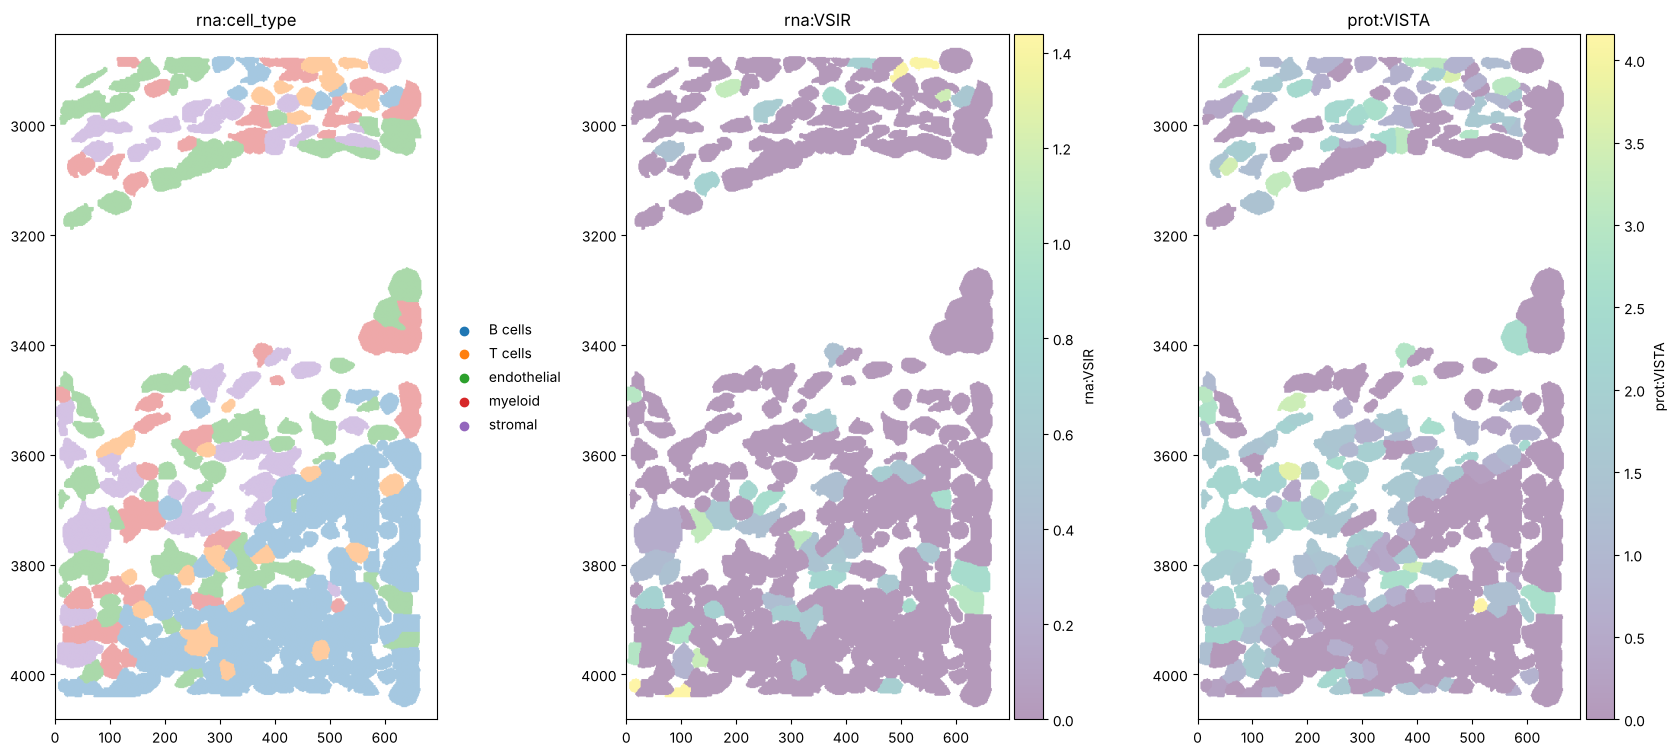

In [17]:
fig, axs = plt.subplots(1, 3, figsize=(16, 9))
for ax, color in zip(axs, ["rna:cell_type", "rna:VSIR", "prot:VISTA"], strict=True):
    tissue.pl.render_labels("cell_labels", color=color, table_name="table").pl.show(ax=ax, title=color)
plt.tight_layout()

Zooming in, the protein stain behind the quantification is shown with the outlines of the cells, colored by the
VISTA intensity measured in each of them.

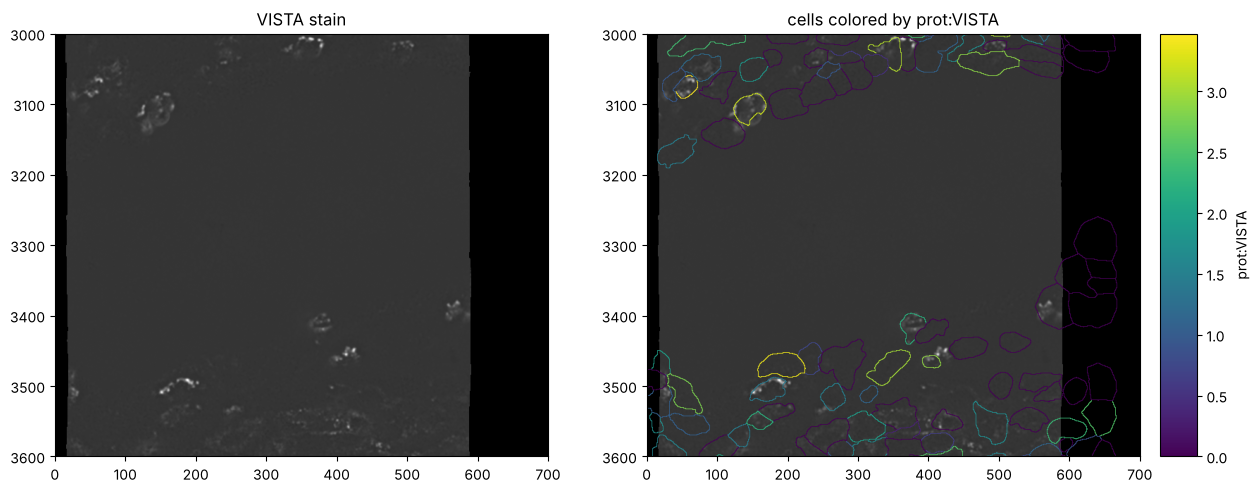

In [18]:
zoom = sdata.query.bounding_box(
    axes=("x", "y"), min_coordinate=[0, 3000], max_coordinate=[700, 3600], target_coordinate_system="global"
)
fig, axs = plt.subplots(1, 2, figsize=(14, 6))
zoom.pl.render_images("morphology_focus", channel="VISTA", cmap="gray", colorbar=False).pl.show(
    ax=axs[0], title="VISTA stain"
)
zoom.pl.render_images("morphology_focus", channel="VISTA", cmap="gray", colorbar=False).pl.render_labels(
    "cell_labels", color="prot:VISTA", table_name="table", fill_alpha=0, outline_alpha=1, contour_px=3
).pl.show(ax=axs[1], title="cells colored by prot:VISTA")

## 10. Save and reload

The MuData table is written in the MuData zarr layout inside the SpatialData store, so it can also be opened directly
with `mudata` (and each modality with `anndata`).

In [19]:
path = Path("xenium_gene_protein.zarr")
sdata.write(path, overwrite=True)
sdata_read = sd.read_zarr(path)
table = sdata_read["table"]
print(type(table).__name__, table.shape, list(table.mod))
print("modality layers kept:", list(table.mod["rna"].layers), list(table.mod["prot"].layers))

MuData (334, 409) ['rna', 'prot']
modality layers kept: ['counts', None] ['intensity', None]


In [20]:
md.read_zarr(path / "tables" / "table")

MuData object with n_obs × n_vars = 334 × 409
  obs:	'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level', 'cell_labels'
  uns:	'spatialdata_attrs'
  obsm:	'spatial'
  2 modalities
    rna:	334 × 405
      obs:	'leiden', 'cell_type'
      var:	'gene_ids', 'feature_types', 'genome'
      uns:	'leiden', 'umap', 'neighbors', 'pca', 'rank_genes_groups', 'log1p'
      obsm:	'X_pca', 'X_umap'
      varm:	'PCs'
      layers:	'counts', None
      obsp:	'connectivities', 'distances'
    prot:	334 × 4
      var:	'gene_ids', 'feature_types', 'genome'
      layers:	'intensity', None